In [4]:

!pip -q install geopandas scikit-learn

import os
import zipfile
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from google.colab import files

# Upload the actual ZIP file
uploaded = files.upload()
zip_name = next(iter(uploaded.keys()))

# Extract all shapefile components
extract_dir = "/content/CAV_dataset"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall(extract_dir)

# Locate the .shp file
shp_files = []

for root, dirs, filenames in os.walk(extract_dir):
    for filename in filenames:
        if filename.lower().endswith(".shp"):
            shp_files.append(os.path.join(root, filename))

if not shp_files:
    raise FileNotFoundError("No .shp file found inside the ZIP.")

print("Shapefile found:", shp_files[0])

# Load geographic data
gdf = gpd.read_file(shp_files[0])

print("Dataset loaded successfully!")
print("Rows and columns:", gdf.shape)
print("Coordinate system:", gdf.crs)
print("Columns:", gdf.columns.tolist())

display(gdf.head())


Saving CAV_25May2021.zip to CAV_25May2021 (3).zip
Shapefile found: /content/CAV_dataset/CPH_MixedModels_25May2021b.shp
Dataset loaded successfully!
Rows and columns: (32270, 6)
Coordinate system: EPSG:4096
Columns: ['Shape_Leng', 'ROAD_FID', 'Mixed_NO2', 'Mixed_UFP', 'Mixed_BC', 'geometry']


,Shape_Leng,ROAD_FID,Mixed_NO2,Mixed_UFP,Mixed_BC,geometry
0,58.821698,1.0,-999999,-999999,-999999.0,"LINESTRING (647726.636 1177142.755, 647680.34 ..."
1,31.898519,2.0,10,18500,0.8,"LINESTRING (650414.236 1170441.732, 650419.634..."
2,36.276259,3.0,9,12800,0.8,"LINESTRING (647858.118 1166878.256, 647853.072..."
3,40.416066,4.0,9,10700,0.7,"LINESTRING (647840.198 1165912.274, 647801.545..."
4,32.734397,5.0,13,14500,1.1,"LINESTRING (647524.426 1165793.088, 647520.091..."


In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

# Define the pollutant columns we want to analyze
usable_cols = ["Mixed_NO2", "Mixed_UFP", "Mixed_BC"]

# Extract the feature matrix from the GeoDataFrame
X = gdf[usable_cols].values

# Scale the pollutant measurements
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train the unsupervised anomaly detector
model = IsolationForest(
    n_estimators=200,
    contamination=0.03,
    random_state=42
)

prediction = model.fit_predict(X_scaled)

# -1 means anomalous; 1 means normal
gdf["anomaly_flag"] = np.where(
    prediction == -1, "Anomaly", "Normal"
)

# Higher score means more unusual
gdf["anomaly_score"] = -model.score_samples(X_scaled)

print("Anomaly detection completed!")
print(gdf["anomaly_flag"].value_counts())

display(
    gdf.loc[
        gdf["anomaly_flag"] == "Anomaly",
        ["ROAD_FID"] + usable_cols + ["anomaly_score"]
    ].sort_values("anomaly_score", ascending=False).head(20)
)

Anomaly detection completed!
anomaly_flag
Normal     31302
Anomaly      968
Name: count, dtype: int64


,ROAD_FID,Mixed_NO2,Mixed_UFP,Mixed_BC,anomaly_score
28430,28431.0,35,-999999,-999999.0,0.767437
16439,16440.0,35,-999999,-999999.0,0.767437
26882,26883.0,23,-999999,-999999.0,0.767052
19898,19899.0,23,-999999,-999999.0,0.767052
27024,27025.0,36,-999999,-999999.0,0.766918
29700,29701.0,36,-999999,-999999.0,0.766918
1575,1576.0,36,-999999,-999999.0,0.766918
12846,12847.0,19,-999999,-999999.0,0.766909
25184,25185.0,10,-999999,-999999.0,0.766755
25077,25078.0,10,-999999,-999999.0,0.766755


In [8]:

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

# Scale the pollutant measurements
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train the unsupervised anomaly detector
model = IsolationForest(
    n_estimators=200,
    contamination=0.03,
    random_state=42
)

prediction = model.fit_predict(X_scaled)

# -1 means anomalous; 1 means normal
gdf["anomaly_flag"] = np.where(
    prediction == -1, "Anomaly", "Normal"
)

# Higher score means more unusual
gdf["anomaly_score"] = -model.score_samples(X_scaled)

print("Anomaly detection completed!")
print(gdf["anomaly_flag"].value_counts())

display(
    gdf.loc[
        gdf["anomaly_flag"] == "Anomaly",
        ["ROAD_FID"] + usable_cols + ["anomaly_score"]
    ].sort_values("anomaly_score", ascending=False).head(20)
)


Anomaly detection completed!
anomaly_flag
Normal     31302
Anomaly      968
Name: count, dtype: int64


,ROAD_FID,Mixed_NO2,Mixed_UFP,Mixed_BC,anomaly_score
28430,28431.0,35,-999999,-999999.0,0.767437
16439,16440.0,35,-999999,-999999.0,0.767437
26882,26883.0,23,-999999,-999999.0,0.767052
19898,19899.0,23,-999999,-999999.0,0.767052
27024,27025.0,36,-999999,-999999.0,0.766918
29700,29701.0,36,-999999,-999999.0,0.766918
1575,1576.0,36,-999999,-999999.0,0.766918
12846,12847.0,19,-999999,-999999.0,0.766909
25184,25185.0,10,-999999,-999999.0,0.766755
25077,25078.0,10,-999999,-999999.0,0.766755


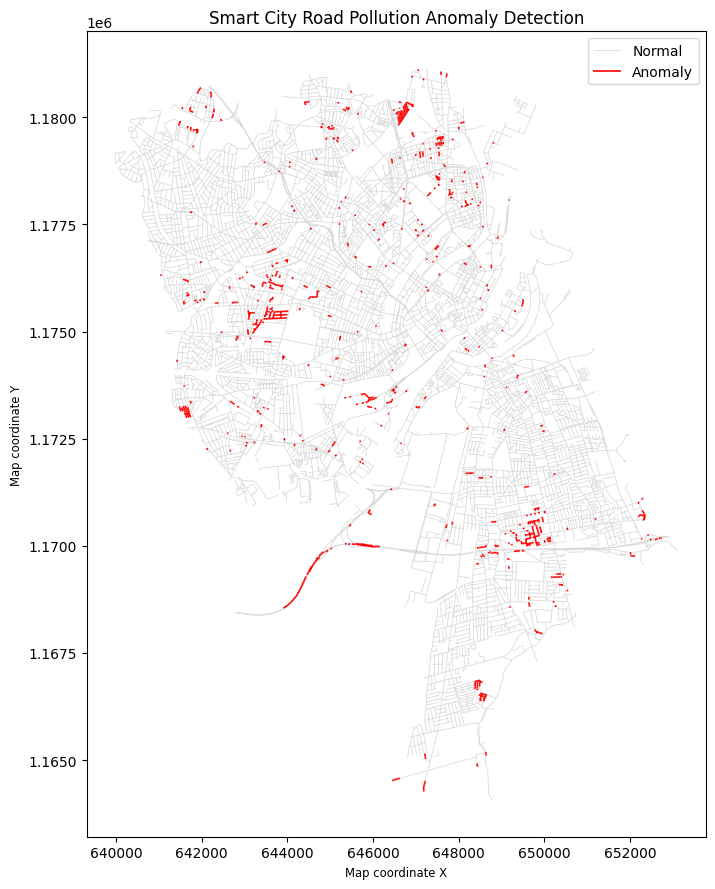

In [9]:

fig, ax = plt.subplots(figsize=(12, 9))

normal = gdf[gdf["anomaly_flag"] == "Normal"]
anomalies = gdf[gdf["anomaly_flag"] == "Anomaly"]

normal.plot(
    ax=ax,
    color="lightgray",
    linewidth=0.5,
    label="Normal"
)

anomalies.plot(
    ax=ax,
    color="red",
    linewidth=1.2,
    label="Anomaly"
)

ax.set_title("Smart City Road Pollution Anomaly Detection")
ax.set_xlabel("Map coordinate X")
ax.set_ylabel("Map coordinate Y")
ax.legend()
plt.tight_layout()
plt.show()


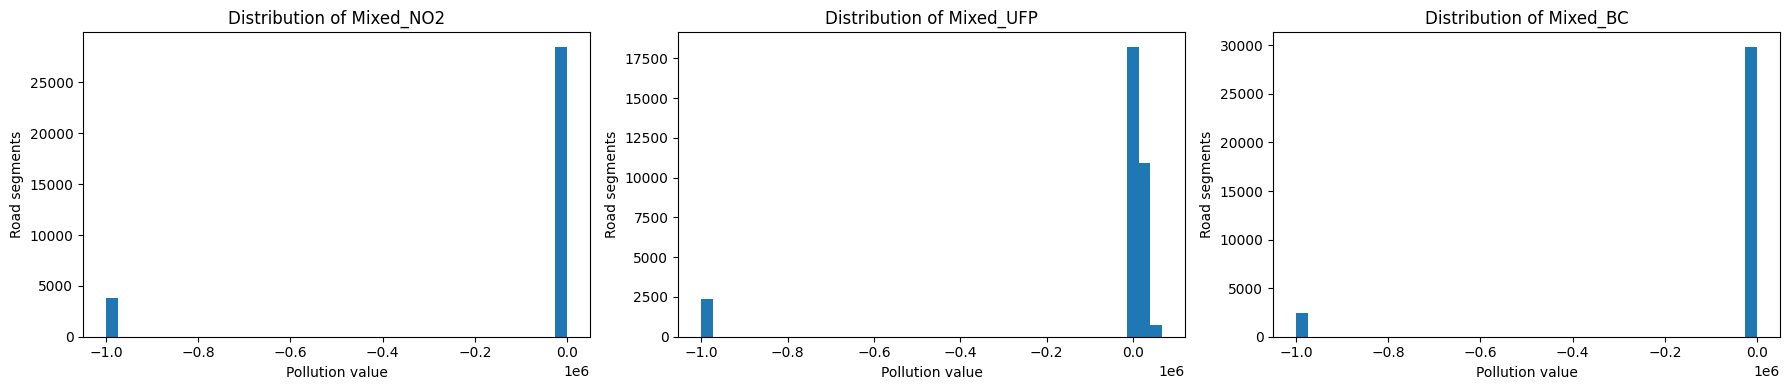

In [10]:

fig, axes = plt.subplots(
    1, len(usable_cols),
    figsize=(6 * len(usable_cols), 4)
)

axes = np.atleast_1d(axes)

for ax, col in zip(axes, usable_cols):
    ax.hist(gdf[col].dropna(), bins=40)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel("Pollution value")
    ax.set_ylabel("Road segments")

plt.tight_layout()
plt.show()


In [12]:

# Export attribute table
csv_output = "/content/CAV_anomaly_results.csv"

attribute_cols = [
    c for c in gdf.columns if c != "geometry"
]

gdf[attribute_cols].to_csv(csv_output, index=False)

# Export spatial results
geojson_output = "/content/CAV_anomaly_results.geojson"
gdf.to_crs("EPSG:4326").to_file(
    geojson_output,
    driver="GeoJSON"
)

print("Total valid road segments:", len(gdf))
print("Anomalies:", (gdf["anomaly_flag"] == "Anomaly").sum())
print(
    "Anomaly percentage:",
    round((gdf["anomaly_flag"] == "Anomaly").mean() * 100, 2),
    "%"
)

files.download(csv_output)
files.download(geojson_output)


Total valid road segments: 32270
Anomalies: 968
Anomaly percentage: 3.0 %


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

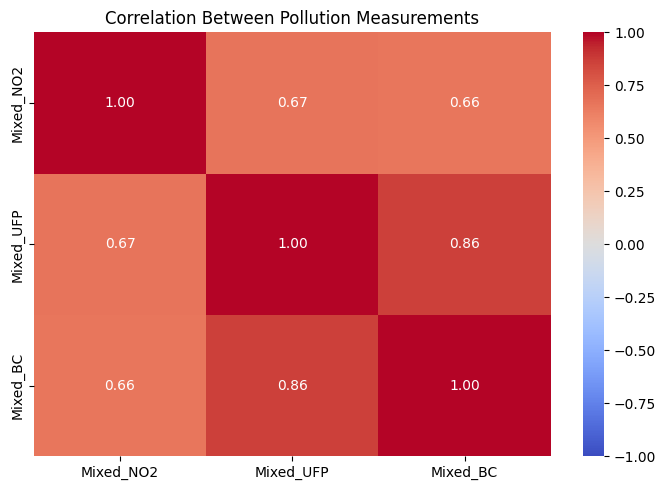

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation = gdf[usable_cols].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Between Pollution Measurements")
plt.tight_layout()
plt.show()